# Week 09 — Home exercise 6: A gap in the line

**Solution proposal.**

Finding the series a line chart would quietly bridge, and drawing one of them both ways.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


def load_panel(emissions_path="../data/co2_emissions.csv", info_path="../data/country_info.csv"):
    """
    Read the emissions and country files and return one clean panel.

    Parameters
    ----------
    emissions_path : str
        Path to the emissions CSV file.
    info_path : str
        Path to the country information CSV file.

    Returns
    -------
    DataFrame
        One row per country per year, with region and income level added,
        rows missing total emissions dropped, the aggregates removed and
        emissions per person added as a column.
    """
    co2 = pd.read_csv(emissions_path)
    co2 = co2.dropna(subset=["co2_total"])
    co2["co2_pc"] = co2["co2_total"] * 1_000_000 / co2["population"]

    info = pd.read_csv(info_path)
    info = info.rename(columns={"incomeLevel": "income_level"})

    panel = co2.merge(
        info[["code", "region", "income_level"]],
        on="code",
        how="left",
        validate="many_to_one",
    )

    return panel[panel["region"] != "Aggregates"]


panel = load_panel()

print(panel.shape, "|", panel["country"].nunique(), "countries")

(4872, 14) | 203 countries


## 1. Which countries have a gap inside the series?

A gap a line can bridge needs a figure on both sides of it. So for each country, take only the years
that **have** a figure, and compare two numbers: how many such years there are, and how many calendar
years lie between the first and the last of them. If the span is longer than the count, some year in
between is missing.

In [2]:
has_figure = panel.dropna(subset=["nat_resources"])

spans = has_figure.groupby("country").agg(
    first_year=("year", "min"),
    last_year=("year", "max"),
    years=("year", "size"),
)
spans["span"] = spans["last_year"] - spans["first_year"] + 1

spans[spans["span"] > spans["years"]]

,first_year,last_year,years,span
country,,,,
Equatorial Guinea,2000,2021,18,22
Timor-Leste,2000,2021,11,22


**Two countries: Timor-Leste, which the lecture drew, and Equatorial Guinea.**

Missing years at the ends are left out by construction. `nat_resources` stops in 2021 for every
country - 2022 and 2023 are simply not published yet - and since the span is measured from the last year
*with* a figure, those two years never count. Countries with no figure at all drop out at the `dropna`
step and never reach the table.

Because the check counts **calendar years** rather than rows, it would also catch a year whose row was
never in the file at all - the worse version of the trap, where there is not even a `NaN` to find.

## 2. Equatorial Guinea, both ways

In [3]:
guinea = panel[panel["country"] == "Equatorial Guinea"].sort_values("year")

guinea[["year", "nat_resources"]].head(7)

,year,nat_resources
1584,2000,88.5923
1585,2001,NaN
1586,2002,NaN
1587,2003,NaN
1588,2004,NaN
1589,2005,56.2891
1590,2006,53.9325


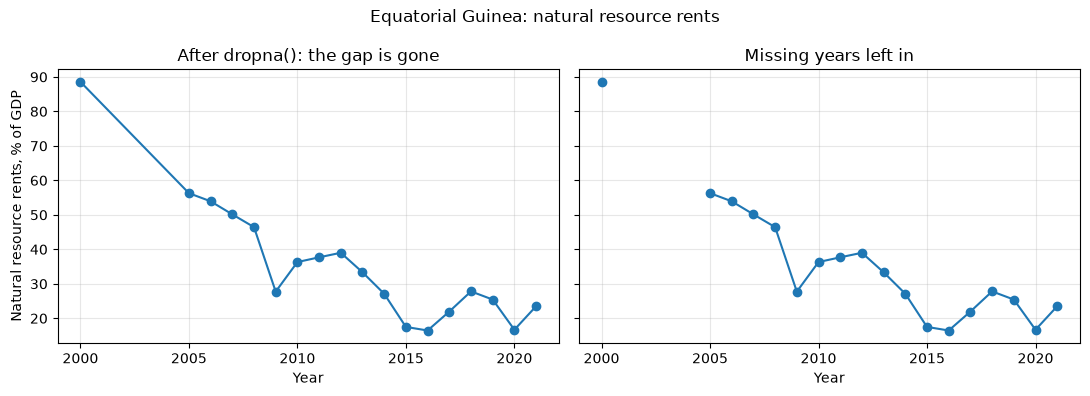

In [4]:
dropped = guinea.dropna(subset=["nat_resources"])

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(11, 4), sharey=True)

axes[0].plot(dropped["year"], dropped["nat_resources"], marker="o")
axes[0].set_title("After dropna(): the gap is gone")
axes[0].set_ylabel("Natural resource rents, % of GDP")

axes[1].plot(guinea["year"], guinea["nat_resources"], marker="o")
axes[1].set_title("Missing years left in")

for ax in axes:
    ax.set_xlabel("Year")
    ax.grid(True, alpha=0.3)

fig.suptitle("Equatorial Guinea: natural resource rents")
fig.tight_layout()

plt.show()

## 3. What the left-hand panel claims

The left panel shows natural resource rents falling steadily from 88.6% of GDP in 2000 to 56.3% in
2005 - a smooth four-year decline of about eight points a year. **None of it is in the file.** There is
no figure for 2001, 2002, 2003 or 2004. Rents could have kept rising, collapsed and recovered, or done
exactly what the line says; the data does not know, and the straight segment is matplotlib joining the
two points it was given.

The right panel says what the data says: a figure in 2000, then nothing, then figures from 2005. The
reader can see that there is something they do not know.

### Things worth noticing

- **`marker="o"` is what keeps 2000 on the right-hand panel.** A point with a `NaN` on both sides has no
  neighbor to join, so a plain line draws nothing for it at all - the year would silently disappear.
  With markers, every observation is drawn whether or not it is connected to anything.
- **The check is a `groupby` with `.agg()`, so it scales.** Two countries is a list you could have found
  by eye; the same three lines find them among 203 countries, or in any other column.
- **Missing at the end is a different kind of missing.** The 2022-2023 gap is about publication lags,
  not about the countries, and treating it as a gap in each country's data would be wrong. Deciding which
  missing values mean what is a judgment, and the code above makes it explicitly.

### What this notebook does NOT do

- **It checks one column.** `gdp_pc`, `electricity` or any other column can have gaps of its own, and
  the same three lines would find them - but nothing here runs them.
- **It does not fill the gap.** Interpolating between 2000 and 2005 would produce a smooth line that
  *looks* like data, which is the same claim as the left-hand panel with extra steps. Leaving the gap is
  the honest default; filling it is a modeling decision that has to be stated.